In [2]:
library(XMR)
library(MRAPSS)
library(TwoSampleMR)
library(extrafont)
library(data.table)
library(dplyr)
library(ggplot2)
library(ggrepel)
library(grid)

In [ ]:
setwd("./real_data_CSA_AFR")

## Fig. 6E

### SHBG to T2D in AFR

In [44]:
case_study = NULL

res_xmr = fread('./AFR_results/XMR.MRres')
res_xmr = res_xmr[res_xmr$exposure=='30830' & res_xmr$outcome=='250.2',]
case_study = rbind(case_study, 
                   res_xmr[,c('exposure','outcome','beta','beta.se','beta.pvalue','nIV','nvalid','Threshold')])
case_study = cbind(case_study, data.frame(method='XMR',population='AFR'))

res_mrapss = fread('./AFR_results/MRAPSS.MRres')
colnames(res_mrapss) = c("exposure","outcome","beta","beta.se","beta.pvalue","tau.sq","nIV","pi0","IVsignal.sum","Threshold")
res_mrapss$nvalid = res_mrapss$nIV*res_mrapss$pi0
res_mrapss = res_mrapss[res_mrapss$exposure=='30830' & res_mrapss$outcome=='250.2',]
case_study = rbind(case_study, data.frame(exposure = res_mrapss$exposure, 
                                          outcome = res_mrapss$outcome, 
                                          beta = res_mrapss$beta,
                                          beta.se = res_mrapss$beta.se,
                                          beta.pvalue = res_mrapss$beta.pvalue,
                                          nIV =  res_mrapss$nIV,
                                          nvalid = res_mrapss$nvalid, 
                                          Threshold = res_mrapss$Threshold,
                                          method = "MRAPSS", 
                                          population = "AFR"))

res_egger = fread('./AFR_results/Egger.MRres')
colnames(res_egger) = c('exposure','outcome','beta','beta.se','beta.pvalue','nIV','Threshold')
res_egger = res_egger[res_egger$exposure=='30830' & res_egger$outcome=='250.2',]
case_study = rbind(case_study, data.frame(exposure = res_egger$exposure, 
                                          outcome = res_egger$outcome, 
                                          beta = res_egger$beta,
                                          beta.se = res_egger$beta.se,
                                          beta.pvalue = res_egger$beta.pvalue,
                                          nIV =  res_egger$nIV,
                                          nvalid = res_egger$nIV, 
                                          Threshold = res_egger$Threshold,
                                          method = "Egger", 
                                          population = "AFR"))

res_weightmod = fread('./AFR_results/Weightmode.MRres')
colnames(res_weightmod) = c('exposure','outcome','beta','beta.se','beta.pvalue','nIV','Threshold')
res_weightmod = res_weightmod[res_weightmod$exposure=='30830' & res_weightmod$outcome=='250.2',]
case_study = rbind(case_study, data.frame(exposure = res_weightmod$exposure, 
                                          outcome = res_weightmod$outcome, 
                                          beta = res_weightmod$beta,
                                          beta.se = res_weightmod$beta.se,
                                          beta.pvalue = res_weightmod$beta.pvalue,
                                          nIV =  res_weightmod$nIV,
                                          nvalid = res_weightmod$nIV, 
                                          Threshold = res_weightmod$Threshold,
                                          method = "Weighted-mode", 
                                          population = "AFR"))

res_cause = fread('./AFR_results/CAUSE.MRres')
colnames(res_cause) = c('exposure','outcome','beta.pvalue','Threshold','nIV','beta','beta.se','method')
res_cause = res_cause[res_cause$exposure=='30830' & res_cause$outcome=='250.2',]
case_study = rbind(case_study, data.frame(exposure = res_cause$exposure, 
                                          outcome = res_cause$outcome, 
                                          beta = res_cause$beta,
                                          beta.se = res_cause$beta.se,
                                          beta.pvalue = res_cause$beta.pvalue,
                                          nIV = res_cause$nIV,
                                          nvalid = res_cause$nIV, 
                                          Threshold = res_cause$Threshold,
                                          method = "CAUSE", 
                                          population = "AFR"))

case_study

exposure,outcome,beta,beta.se,beta.pvalue,nIV,nvalid,Threshold,method,population
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<chr>,<chr>
30830,250.2,-0.16390000,0.04794239,0.00063026,1206,145.286441,5e-05,XMR,AFR
30830,250.2,-0.09993071,0.08129896,0.21901000,39,7.925321,5e-05,MRAPSS,AFR
30830,250.2,0.08524469,0.20016850,0.67267364,39,39.000000,5e-05,Egger,AFR
30830,250.2,-0.16388109,0.09243169,0.08424533,39,39.000000,5e-05,Weighted-mode,AFR
30830,250.2,0.01411429,0.24193619,0.99997994,39,39.000000,5e-05,CAUSE,AFR


In [45]:
afr = case_study

afr$Lower_CI = afr$beta - 1.96*afr$beta.se
afr$Upper_CI = afr$beta + 1.96*afr$beta.se
afr$beta_CI_text = paste0(round(afr$beta,2), " (", round(afr$Lower_CI,2), ",", round(afr$Upper_CI,2), ")")
afr$IV_text = afr$nIV
afr$IV_text[1] = paste0(afr$nIV[1], " (", round(afr$nvalid[1]), ")")
afr$IV_text[2] = paste0(afr$nIV[2], " (", round(afr$nvalid[2]), ")")
afr$sig = as.character(afr$beta.pvalue<0.05)
afr$method <- gsub("Weighted-mode", "Weighted\nmode", afr$method)

Warning message in geom_segment(aes(x = 0, xend = 0, y = 0.5, yend = 5.3), linetype = "dashed", :
“All aesthetics have length 1, but the data has 5 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing a single row.”
Warning message in geom_segment(aes(x = -1.38, xend = 2.8, y = 5.3, yend = 5.3), :
“All aesthetics have length 1, but the data has 5 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing a single row.”
Warning message in geom_segment(aes(x = 0, xend = 0, y = 0.5, yend = 5.3), linetype = "dashed", :
“All aesthetics have length 1, but the data has 5 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing a single row.”
Warning message in geom_segment(aes(x = -1.38, xend = 2.8, y = 5.3, yend = 5.3), :
“All aesthetics have length 1, but the data has 5 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing a single row.”


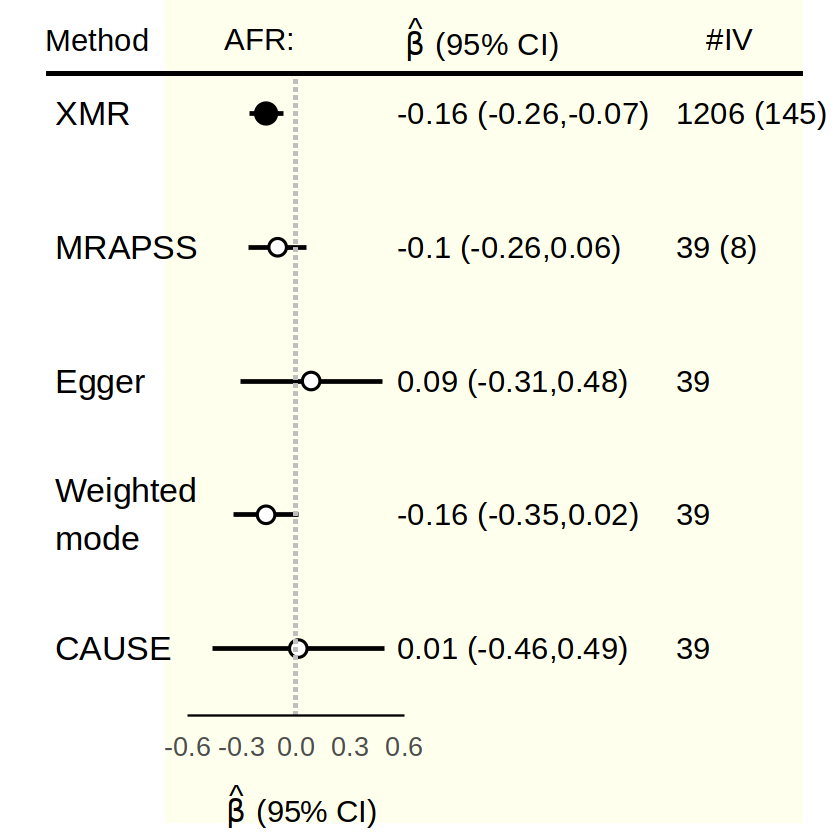

In [51]:
labels <- data.frame(
  x = c(-1.1, -0.2, 1.03, 2.4),
  y = c(5.55, 5.55, 5.55, 5.55),
  label = c("'Method'", "'AFR:'", "hat(beta)~'(95% CI)'", "'#IV'")
)

afr$method <- factor(afr$method, levels = c('XMR','MRAPSS','Egger','Weighted\nmode','CAUSE'))

plot <- ggplot(afr, aes(y = method, x = beta)) +
  #geom_rect(aes(xmin = -0.6, xmax = 2.8, ymin = -Inf, ymax = Inf), fill = "yellow", alpha = 0.2) +
  annotation_custom(
      grob = rectGrob(
        gp = gpar(fill = "yellow", alpha = 0.07, col = NA)  
      ),
      xmin = -0.72, xmax = 2.8, ymin = -0.3, ymax = 6.6     
    ) +
  coord_cartesian(clip = "off") + 
  geom_linerange(aes(xmin = Lower_CI, xmax = Upper_CI), size = 1) +

  geom_point(aes(shape = sig, size = sig, fill = sig), color = "black", stroke = 1) +
  #geom_vline(xintercept = 0, linetype = "dashed", color = "grey", size=1.1, yend = 5.3) +
  geom_segment(aes(x = 0, xend = 0, y = 0.5, yend = 5.3), linetype = "dashed", color = "grey", size = 1) +

  scale_shape_manual(values = c('TRUE' = 21, 'FALSE' = 21)) +  
  scale_size_manual(values = c('TRUE' = 5, 'FALSE' = 4)) + 
  scale_fill_manual(values = c("TRUE" = "black", "FALSE" = "white")) + 
  scale_y_discrete(limits = rev(levels(afr$method))) + 

  scale_x_continuous(limits = c(-1.38, 2.8), breaks = seq(-0.6, 0.6, 0.3),  
                     labels = c("-0.6", "-0.3", "0.0", "0.3", "0.6")) +
  geom_text(aes(x = -1.33, label = method), hjust = 0, size = 7) +

  geom_text(aes(x = 0.56, label = beta_CI_text), hjust = 0, size = 6.5) + 
  geom_text(aes(x = 2.1, label = IV_text), hjust = 0, size = 6.5) +     
  geom_segment(aes(x = -1.38, xend = 2.8, y = 5.3, yend = 5.3), size = 1) +  

  geom_text(data = labels, aes(x = x, y = y, label = label), size = 6.5, fontface = "bold", parse = TRUE) +

  #geom_vline(xintercept = 0, linetype = "dashed", color = "grey", size = 1, yend = 5.3) +

  annotate("segment", x = -0.6, xend = 0.6, y = 0.5, yend = 0.5, color = "black", size = 0.5) +
  #coord_cartesian(xlim = c(-0.5, 0.5)) +

  theme_minimal() +
  theme(
    panel.grid.major.y = element_blank(),  
    panel.grid.major.x = element_blank(),  
    panel.grid.minor = element_blank(),    
    axis.title.y = element_blank(),        
    axis.title.x = element_text(size = 18, margin = margin(t = 14), hjust = 0.32), 
    axis.text.y = element_blank(), #element_text(size = 28, margin = margin(r = -35)), 
    axis.text.x = element_text(size = 16, margin = margin(t = 5)),
    axis.line.x = element_blank(),         
    axis.ticks.x = element_blank(),       
    plot.margin = margin(t = 20, r = 0, b = 3, l = 5),        
    legend.position = "none"                                       
  ) +
  labs(
    x = expression(hat(beta)~'(95% CI)') #"Estimated effect (95% CI)" 
  )

plot

ggsave('./case_AFR.png', width = 14.1, height = 9)

### SHBG to T2D in CSA

In [52]:
case_study = NULL

res_xmr = fread('./CSA_results/XMR.MRres')
res_xmr = res_xmr[res_xmr$exposure=='30830' & res_xmr$outcome=='250.2',]
case_study = rbind(case_study, 
                   res_xmr[,c('exposure','outcome','beta','beta.se','beta.pvalue','nIV','nvalid','Threshold')])
case_study = cbind(case_study, data.frame(method='XMR',population='CSA'))

res_mrapss = fread('./CSA_results/MRAPSS.MRres')
colnames(res_mrapss) = c("exposure","outcome","beta","beta.se","beta.pvalue","tau.sq","nIV","pi0","IVsignal.sum","Threshold")
res_mrapss$nvalid = res_mrapss$nIV*res_mrapss$pi0
res_mrapss = res_mrapss[res_mrapss$exposure=='30830' & res_mrapss$outcome=='250.2',]
case_study = rbind(case_study, data.frame(exposure = res_mrapss$exposure, 
                                          outcome = res_mrapss$outcome, 
                                          beta = res_mrapss$beta,
                                          beta.se = res_mrapss$beta.se,
                                          beta.pvalue = res_mrapss$beta.pvalue,
                                          nIV =  res_mrapss$nIV,
                                          nvalid = res_mrapss$nvalid, 
                                          Threshold = res_mrapss$Threshold,
                                          method = "MRAPSS", 
                                          population = "CSA"))

res_egger = fread('./CSA_results/Egger.MRres')
colnames(res_egger) = c('exposure','outcome','beta','beta.se','beta.pvalue','nIV','Threshold')
res_egger = res_egger[res_egger$exposure=='30830' & res_egger$outcome=='250.2',]
case_study = rbind(case_study, data.frame(exposure = res_egger$exposure, 
                                          outcome = res_egger$outcome, 
                                          beta = res_egger$beta,
                                          beta.se = res_egger$beta.se,
                                          beta.pvalue = res_egger$beta.pvalue,
                                          nIV =  res_egger$nIV,
                                          nvalid = res_egger$nIV, 
                                          Threshold = res_egger$Threshold,
                                          method = "Egger", 
                                          population = "CSA"))

res_weightmod = fread('./CSA_results/Weightmode.MRres')
colnames(res_weightmod) = c('exposure','outcome','beta','beta.se','beta.pvalue','nIV','Threshold')
res_weightmod = res_weightmod[res_weightmod$exposure=='30830' & res_weightmod$outcome=='250.2',]
case_study = rbind(case_study, data.frame(exposure = res_weightmod$exposure, 
                                          outcome = res_weightmod$outcome, 
                                          beta = res_weightmod$beta,
                                          beta.se = res_weightmod$beta.se,
                                          beta.pvalue = res_weightmod$beta.pvalue,
                                          nIV =  res_weightmod$nIV,
                                          nvalid = res_weightmod$nIV, 
                                          Threshold = res_weightmod$Threshold,
                                          method = "Weighted-mode", 
                                          population = "CSA"))

res_cause = fread('./CSA_results/CAUSE.MRres')
colnames(res_cause) = c('exposure','outcome','beta.pvalue','Threshold','nIV','beta','beta.se','method')
res_cause = res_cause[res_cause$exposure=='30830' & res_cause$outcome=='250.2',]
case_study = rbind(case_study, data.frame(exposure = res_cause$exposure, 
                                          outcome = res_cause$outcome, 
                                          beta = res_cause$beta,
                                          beta.se = res_cause$beta.se,
                                          beta.pvalue = res_cause$beta.pvalue,
                                          nIV = res_cause$nIV,
                                          nvalid = res_cause$nIV, 
                                          Threshold = res_cause$Threshold,
                                          method = "CAUSE", 
                                          population = "CSA"))

case_study

exposure,outcome,beta,beta.se,beta.pvalue,nIV,nvalid,Threshold,method,population
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<chr>,<chr>
30830,250.2,-0.15350000,0.04501928,0.00065066,1124,139.878891,5e-05,XMR,CSA
30830,250.2,-0.06916157,0.07477415,0.35500000,39,6.138697,5e-05,MRAPSS,CSA
30830,250.2,0.06535882,0.17079143,0.70414512,39,39.000000,5e-05,Egger,CSA
30830,250.2,-0.08867624,0.06966703,0.21080112,39,39.000000,5e-05,Weighted-mode,CSA
30830,250.2,-0.09897274,0.05880576,0.25103909,39,39.000000,5e-05,CAUSE,CSA


In [53]:
csa = case_study

csa$Lower_CI = csa$beta - 1.96*csa$beta.se
csa$Upper_CI = csa$beta + 1.96*csa$beta.se
csa$beta_CI_text = paste0(round(csa$beta,2), " (", round(csa$Lower_CI,2), ",", round(csa$Upper_CI,2), ")")
csa$IV_text = csa$nIV
csa$IV_text[1] = paste0(csa$nIV[1], " (", round(csa$nvalid[1]), ")")
csa$IV_text[2] = paste0(csa$nIV[2], " (", round(csa$nvalid[2]), ")")
csa$sig = as.character(csa$beta.pvalue<0.05)
csa$method <- gsub("Weighted-mode", "Weighted\nmode", csa$method)

Warning message in geom_segment(aes(x = 0, xend = 0, y = 0.5, yend = 5.3), linetype = "dashed", :
“All aesthetics have length 1, but the data has 5 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing a single row.”
Warning message in geom_segment(aes(x = -0.5, xend = 2.8, y = 5.3, yend = 5.3), :
“All aesthetics have length 1, but the data has 5 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing a single row.”
Warning message in geom_segment(aes(x = 0, xend = 0, y = 0.5, yend = 5.3), linetype = "dashed", :
“All aesthetics have length 1, but the data has 5 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing a single row.”
Warning message in geom_segment(aes(x = -0.5, xend = 2.8, y = 5.3, yend = 5.3), :
“All aesthetics have length 1, but the data has 5 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing a single row.”


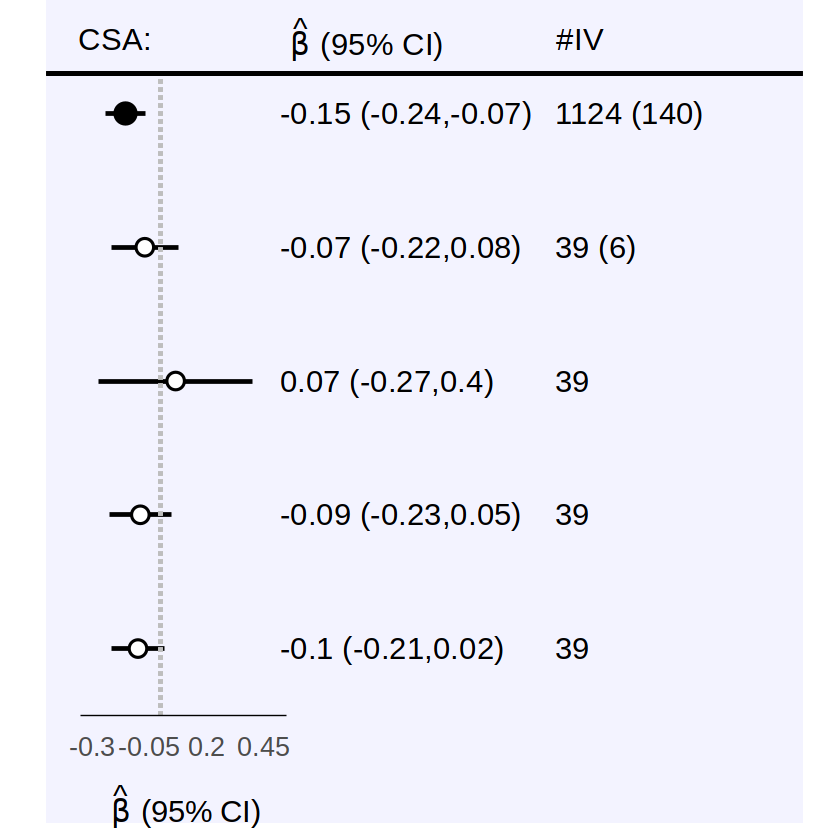

In [57]:
labels <- data.frame(
  x = c(-0.2, 0.9, 1.83),
  y = c(5.55, 5.55, 5.55),
  label = c("'CSA:'", "hat(beta)~'(95% CI)'", "'#IV'")
)

csa$method <- factor(csa$method, levels = c('XMR','MRAPSS','Egger','Weighted\nmode','CAUSE'))

plot <- ggplot(csa, aes(y = method, x = beta)) +
  #geom_rect(aes(xmin = -0.6, xmax = 2.8, ymin = -Inf, ymax = Inf), fill = "yellow", alpha = 0.2) +
  annotation_custom(
      grob = rectGrob(
        gp = gpar(fill = "blue", alpha = 0.05, col = NA)  
      ),
      xmin = -0.5, xmax = 2.8, ymin = -0.3, ymax = 6.6    
    ) +

  coord_cartesian(clip = "off") + 
  geom_linerange(aes(xmin = Lower_CI, xmax = Upper_CI), size = 1) +

  geom_point(aes(shape = sig, size = sig, fill = sig), color = "black", stroke = 1) +
  #geom_vline(xintercept = 0, linetype = "dashed", color = "grey", size=1.1, yend = 5.3) +
  geom_segment(aes(x = 0, xend = 0, y = 0.5, yend = 5.3), linetype = "dashed", color = "grey", size = 1) +

  scale_shape_manual(values = c('TRUE' = 21, 'FALSE' = 21)) +
  scale_size_manual(values = c('TRUE' = 5, 'FALSE' = 4)) +  
  scale_fill_manual(values = c("TRUE" = "black", "FALSE" = "white")) +  
  scale_y_discrete(limits = rev(levels(afr$method))) +  

  scale_x_continuous(limits = c(-0.5, 2.8), breaks = seq(-0.3, 0.45, 0.25),  
                     labels = c("-0.3", "-0.05", "0.2", "0.45")) +
  #geom_text(aes(x = -1.27, label = method), hjust = 0, size = 9.8) +

  geom_text(aes(x = 0.52, label = beta_CI_text), hjust = 0, size = 6.5) +  
  geom_text(aes(x = 1.72, label = IV_text), hjust = 0, size = 6.5) +    
  geom_segment(aes(x = -0.5, xend = 2.8, y = 5.3, yend = 5.3), size = 1) +  

  geom_text(data = labels, aes(x = x, y = y, label = label), size = 6.5, fontface = "bold", parse = TRUE) +
  
  #geom_vline(xintercept = 0, linetype = "dashed", color = "grey", size = 1, yend = 5.3) +

  annotate("segment", x = -0.35, xend = 0.55, y = 0.5, yend = 0.5, color = "black", size = 0.3) +
  #coord_cartesian(xlim = c(-0.5, 0.5)) +
  theme_minimal() +
  theme(
    panel.grid.major.y = element_blank(),  
    panel.grid.major.x = element_blank(),  
    panel.grid.minor = element_blank(),    
    axis.title.y = element_blank(),       
    axis.title.x = element_text(size = 18, margin = margin(t = 14), hjust = 0.15), 
    axis.text.y = element_blank(), #element_text(size = 28, margin = margin(r = -35)), 
    axis.text.x = element_text(size = 16, margin = margin(t = 5)),  
    axis.line.x = element_blank(),         
    axis.ticks.x = element_blank(),        
    plot.margin = margin(t = 20, r = 0, b = 3, l = 5),            
    legend.position = "none"                                       
  ) +
  labs(
    x = expression(hat(beta)~'(95% CI)') #"Estimated effect (95% CI)" 
  )

plot
ggsave('./case_CSA.png', width = 14.1, height = 9)

### SHBG to T2D in EAS

In [65]:
case_study = read.csv('case_study_EAS.csv', row.names = 1)

In [66]:
case_study

,exposure,outcome,beta,beta.se,beta.pvalue,nIV,nvalid,Threshold,method,population
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<chr>,<chr>
1,30830,250.2,-0.034800000,0.02133831,0.1027600,1040,99.678248,5e-05,XMR,EAS
2,30830,250.2,0.017793809,0.04141886,0.6674800,20,3.841166,5e-05,MRAPSS,EAS
3,30830,250.2,0.002929059,0.07672851,0.9699689,20,20.000000,5e-05,Egger,EAS
4,30830,250.2,0.008340131,0.01213988,0.5003811,20,20.000000,5e-05,Weighted-mode,EAS
5,30830,250.2,0.003524847,0.03246145,0.9701544,20,20.000000,5e-05,CAUSE,EAS


In [67]:
eas = case_study

eas$Lower_CI = eas$beta - 1.96*eas$beta.se
eas$Upper_CI = eas$beta + 1.96*eas$beta.se
eas$beta_CI_text = paste0(round(eas$beta,2), " (", round(eas$Lower_CI,2), ",", round(eas$Upper_CI,2), ")")
eas$IV_text = eas$nIV
eas$IV_text[1] = paste0(eas$nIV[1], " (", round(eas$nvalid[1]), ")")
eas$IV_text[2] = paste0(eas$nIV[2], " (", round(eas$nvalid[2]), ")")
eas$sig = as.character(eas$beta.pvalue<0.05)
eas$method <- gsub("Weighted-mode", "Weighted\nmode", eas$method)

Warning message in geom_segment(aes(x = 0, xend = 0, y = 0.5, yend = 5.3), linetype = "dashed", :
“All aesthetics have length 1, but the data has 5 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing a single row.”
Warning message in geom_segment(aes(x = -0.27, xend = 1.1, y = 5.3, yend = 5.3), :
“All aesthetics have length 1, but the data has 5 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing a single row.”
Warning message in geom_segment(aes(x = 0, xend = 0, y = 0.5, yend = 5.3), linetype = "dashed", :
“All aesthetics have length 1, but the data has 5 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing a single row.”
Warning message in geom_segment(aes(x = -0.27, xend = 1.1, y = 5.3, yend = 5.3), :
“All aesthetics have length 1, but the data has 5 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing a single row.”


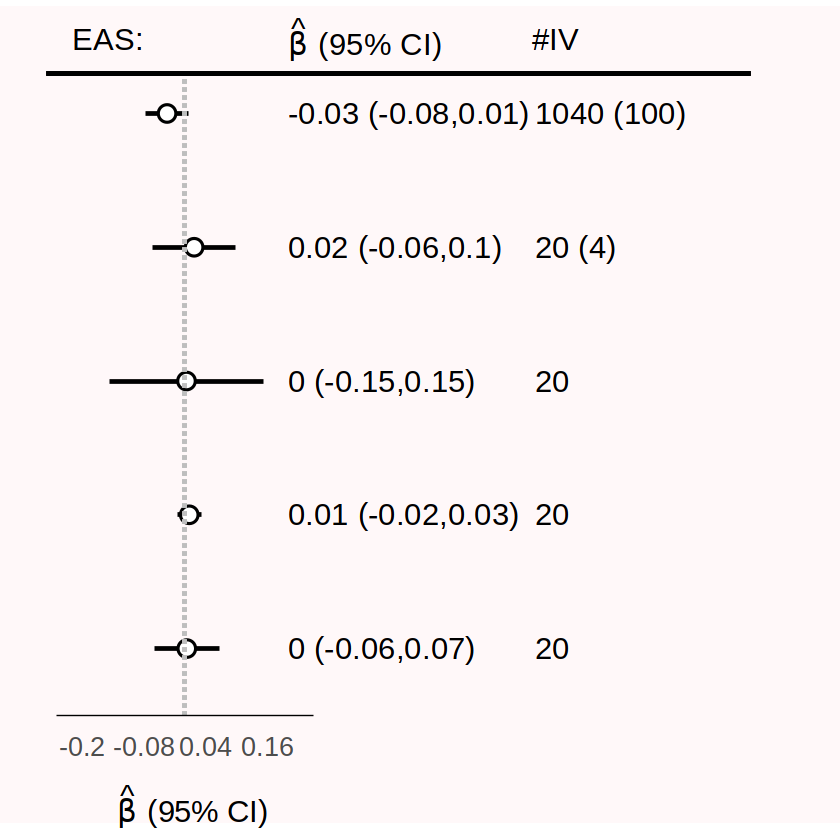

In [82]:
labels <- data.frame(
  x = c(-0.15, 0.35, 0.72),
  y = c(5.55, 5.55, 5.55),
  label = c("'EAS:'", "hat(beta)~'(95% CI)'", "'#IV'"),
  stringsAsFactors = FALSE
)

eas$method <- factor(eas$method, levels = c('XMR','MRAPSS','Egger','Weighted\nmode','CAUSE'))

plot <- ggplot(eas, aes(y = method, x = beta)) +
  #geom_rect(aes(xmin = -0.6, xmax = 2.8, ymin = -Inf, ymax = Inf), fill = "yellow", alpha = 0.2) +
  annotation_custom(
      grob = rectGrob(
        gp = gpar(fill = "pink", alpha = 0.11, col = NA)  
      ),
      xmin = -0.5, xmax = 2.4, ymin = -0.3, ymax = 5.8    
    ) +
  
  coord_cartesian(clip = "off") + 
  geom_linerange(aes(xmin = Lower_CI, xmax = Upper_CI), size = 1) +

  geom_point(aes(shape = sig, size = sig, fill = sig), color = "black", stroke = 1) +
  #geom_vline(xintercept = 0, linetype = "dashed", color = "grey", size=1.1, yend = 5.3) +
  geom_segment(aes(x = 0, xend = 0, y = 0.5, yend = 5.3), linetype = "dashed", color = "grey", size = 1) +

  scale_shape_manual(values = c('TRUE' = 21, 'FALSE' = 21)) + 
  scale_size_manual(values = c('TRUE' = 5, 'FALSE' = 4)) + 
  scale_fill_manual(values = c("TRUE" = "black", "FALSE" = "white")) +  
  scale_y_discrete(limits = rev(levels(afr$method))) + 

  scale_x_continuous(limits = c(-0.27, 1.2), breaks = seq(-0.2, 0.16, 0.12),  
                     labels = c("-0.2", "-0.08", "0.04", "0.16")) +
  #geom_text(aes(x = -1.27, label = method), hjust = 0, size = 9.8) +

  geom_text(aes(x = 0.2, label = beta_CI_text), hjust = 0, size = 6.5) +  
  geom_text(aes(x = 0.68, label = IV_text), hjust = 0, size = 6.5) +       
  geom_segment(aes(x = -0.27, xend = 1.1, y = 5.3, yend = 5.3), size = 1) +  

  geom_text(data = labels, aes(x = x, y = y, label = label), size = 6.5, fontface = "bold", parse = TRUE) +

  #geom_vline(xintercept = 0, linetype = "dashed", color = "grey", size = 1, yend = 5.3) +

  annotate("segment", x = -0.25, xend = 0.25, y = 0.5, yend = 0.5, color = "black", size = 0.3) +
  #coord_cartesian(xlim = c(-0.5, 0.5)) +

  theme_minimal() +
  theme(
    panel.grid.major.y = element_blank(),  
    panel.grid.major.x = element_blank(), 
    panel.grid.minor = element_blank(),   
    axis.title.y = element_blank(),        
    axis.title.x = element_text(size = 18, margin = margin(t = 14), hjust = 0.16),
    axis.text.y = element_blank(), #element_text(size = 28, margin = margin(r = -35)),  
    axis.text.x = element_text(size = 16, margin = margin(t = 5)), 
    axis.line.x = element_blank(),        
    axis.ticks.x = element_blank(),        
    plot.margin = margin(t = 20, r = 0, b = 3, l = 5),          
    legend.position = "none"                                
  ) +
  labs(
    x = expression(hat(beta)~'(95% CI)') #"Estimated effect (95% CI)" 
  )


plot

ggsave('./case_EAS.png', width = 14.1, height = 9)

### SHBG to T2D in EUR

In [76]:
case_study = NULL

case_study = rbind(case_study, 
                   data.frame(exposure='30830', outcome='250.2', beta=NA, beta.se=NA, beta.pvalue=NA,
                              nIV=NA, nvalid=NA, Threshold=5e-5, method='XMR', population='EUR'))

res_mrapss = fread('./EUR_results_in_AFR/MRAPSS.MRres')
colnames(res_mrapss) = c("exposure","outcome","beta","beta.se","beta.pvalue","tau.sq","nIV","pi0","IVsignal.sum","Threshold")
res_mrapss$nvalid = res_mrapss$nIV*res_mrapss$pi0
res_mrapss = res_mrapss[res_mrapss$exposure=='30830' & res_mrapss$outcome=='250.2',]
case_study = rbind(case_study, data.frame(exposure = res_mrapss$exposure, 
                                          outcome = res_mrapss$outcome, 
                                          beta = res_mrapss$beta,
                                          beta.se = res_mrapss$beta.se,
                                          beta.pvalue = res_mrapss$beta.pvalue,
                                          nIV =  res_mrapss$nIV,
                                          nvalid = res_mrapss$nvalid, 
                                          Threshold = res_mrapss$Threshold,
                                          method = "MRAPSS", 
                                          population = "EUR"))

res_egger = fread('./EUR_results_in_AFR/Egger.MRres')
colnames(res_egger) = c('exposure','outcome','beta','beta.se','beta.pvalue','nIV','Threshold')
res_egger = res_egger[res_egger$exposure=='30830' & res_egger$outcome=='250.2',]
case_study = rbind(case_study, data.frame(exposure = res_egger$exposure, 
                                          outcome = res_egger$outcome, 
                                          beta = res_egger$beta,
                                          beta.se = res_egger$beta.se,
                                          beta.pvalue = res_egger$beta.pvalue,
                                          nIV =  res_egger$nIV,
                                          nvalid = res_egger$nIV, 
                                          Threshold = res_egger$Threshold,
                                          method = "Egger", 
                                          population = "EUR"))

res_weightmod = fread('./EUR_results_in_AFR/Weightmode.MRres')
colnames(res_weightmod) = c('exposure','outcome','beta','beta.se','beta.pvalue','nIV','Threshold')
res_weightmod = res_weightmod[res_weightmod$exposure=='30830' & res_weightmod$outcome=='250.2',]
case_study = rbind(case_study, data.frame(exposure = res_weightmod$exposure, 
                                          outcome = res_weightmod$outcome, 
                                          beta = res_weightmod$beta,
                                          beta.se = res_weightmod$beta.se,
                                          beta.pvalue = res_weightmod$beta.pvalue,
                                          nIV =  res_weightmod$nIV,
                                          nvalid = res_weightmod$nIV, 
                                          Threshold = res_weightmod$Threshold,
                                          method = "Weighted-mode", 
                                          population = "EUR"))

res_cause = fread('./EUR_results_in_AFR/CAUSE.MRres')
colnames(res_cause) = c('exposure','outcome','beta.pvalue','Threshold','nIV','beta','beta.se','method')
res_cause = res_cause[res_cause$exposure=='30830' & res_cause$outcome=='250.2',]
case_study = rbind(case_study, data.frame(exposure = res_cause$exposure, 
                                          outcome = res_cause$outcome, 
                                          beta = res_cause$beta,
                                          beta.se = res_cause$beta.se,
                                          beta.pvalue = res_cause$beta.pvalue,
                                          nIV = res_cause$nIV,
                                          nvalid = res_cause$nIV, 
                                          Threshold = res_cause$Threshold,
                                          method = "CAUSE", 
                                          population = "EUR"))

case_study

exposure,outcome,beta,beta.se,beta.pvalue,nIV,nvalid,Threshold,method,population
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<chr>,<chr>
30830,250.2,NA,NA,NA,NA,NA,5e-05,XMR,EUR
30830,250.2,-0.09460543,0.01374684,5.902700e-12,931,372.6232,5e-05,MRAPSS,EUR
30830,250.2,0.03486140,0.03069454,2.568439e-01,349,349.0000,5e-08,Egger,EUR
30830,250.2,-0.04818708,0.02035623,1.847032e-02,349,349.0000,5e-08,Weighted-mode,EUR
30830,250.2,-0.10010895,0.01368537,1.825355e-04,931,931.0000,5e-05,CAUSE,EUR


In [79]:
eur = case_study

eur$Lower_CI = eur$beta - 1.96*eur$beta.se
eur$Upper_CI = eur$beta + 1.96*eur$beta.se
eur$beta_CI_text = NULL
eur$beta_CI_text[2:5] = paste0(round(eur$beta[2:5],2), " (", round(eur$Lower_CI[2:5],2), ",", round(eur$Upper_CI[2:5],2), ")")
eur$IV_text = eur$nIV
#eur$IV_text[1] = paste0(eur$nIV[1], " (", round(eur$nvalid[1]), ")")
eur$IV_text[2] = paste0(eur$nIV[2], " (", round(eur$nvalid[2]), ")")
eur$sig = as.character(eur$beta.pvalue<0.05)
eur$method <- gsub("Weighted-mode", "Weighted\nmode", eur$method)

Warning message in geom_segment(aes(x = 0, xend = 0, y = 0.5, yend = 5.3), linetype = "dashed", :
“All aesthetics have length 1, but the data has 5 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing a single row.”
Warning message in geom_segment(aes(x = -0.2, xend = 0.6, y = 5.3, yend = 5.3), :
“All aesthetics have length 1, but the data has 5 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing a single row.”
Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_point()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_text()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_text()`).”
Warning message in geom_segment(aes(x = 0, xend = 0, y = 0.5, yend = 5.3),

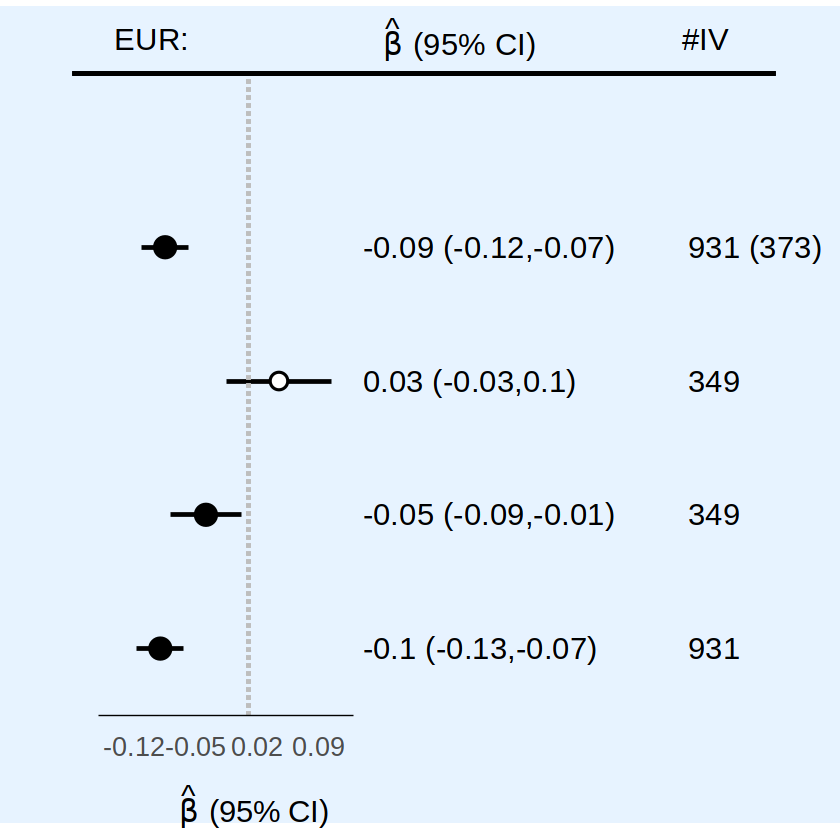

In [89]:
labels <- data.frame(
  x = c(-0.11, 0.24, 0.52),
  y = c(5.55, 5.55, 5.55),
  label = c("'EUR:'", "hat(beta)~'(95% CI)'", "'#IV'")
)

eur$method <- factor(eur$method, levels = c('XMR','MRAPSS','Egger','Weighted\nmode','CAUSE'))

plot <- ggplot(eur, aes(y = method, x = beta)) +
  #geom_rect(aes(xmin = -0.6, xmax = 2.8, ymin = -Inf, ymax = Inf), fill = "yellow", alpha = 0.2) +
  annotation_custom(
      grob = rectGrob(
        gp = gpar(fill = "#3399FF", alpha = 0.12, col = NA)  
      ),
      xmin = -0.5, xmax = 2.6, ymin = -0.3, ymax = 5.8   
    ) +
 
  coord_cartesian(clip = "off") + 
  geom_linerange(aes(xmin = Lower_CI, xmax = Upper_CI), size = 1) +
  
  geom_point(aes(shape = sig, size = sig, fill = sig), color = "black", stroke = 1) +
  #geom_vline(xintercept = 0, linetype = "dashed", color = "grey", size=1.1, yend = 5.3) +
  geom_segment(aes(x = 0, xend = 0, y = 0.5, yend = 5.3), linetype = "dashed", color = "grey", size = 1) +
  
  scale_shape_manual(values = c('TRUE' = 21, 'FALSE' = 21)) + 
  scale_size_manual(values = c('TRUE' = 5, 'FALSE' = 4)) + 
  scale_fill_manual(values = c("TRUE" = "black", "FALSE" = "white")) +
  scale_y_discrete(limits = rev(levels(afr$method))) + 

  scale_x_continuous(limits = c(-0.23, 0.63), breaks = seq(-0.13, 0.11, 0.07), 
                     labels = c("-0.12", "-0.05", "0.02", "0.09")) +
  #geom_text(aes(x = -1.27, label = method), hjust = 0, size = 9.8) +

  geom_text(aes(x = 0.13, label = beta_CI_text), hjust = 0, size = 6.5) +  
  geom_text(aes(x = 0.5, label = IV_text), hjust = 0, size = 6.5) +       
  geom_segment(aes(x = -0.2, xend = 0.6, y = 5.3, yend = 5.3), size = 1) +  

  geom_text(data = labels, aes(x = x, y = y, label = label), size = 6.5, fontface = "bold", parse = TRUE) +

  #geom_vline(xintercept = 0, linetype = "dashed", color = "grey", size = 1, yend = 5.3) +

  annotate("segment", x = -0.17, xend = 0.12, y = 0.5, yend = 0.5, color = "black", size = 0.3) +
  #coord_cartesian(xlim = c(-0.5, 0.5)) +
  theme_minimal() +
  theme(
    panel.grid.major.y = element_blank(),  
    panel.grid.major.x = element_blank(), 
    panel.grid.minor = element_blank(),  
    axis.title.y = element_blank(),      
    axis.title.x = element_text(size = 18, margin = margin(t = 14), hjust = 0.25), 
    axis.text.y = element_blank(), #element_text(size = 28, margin = margin(r = -35)), 
    axis.text.x = element_text(size = 16, margin = margin(t = 5)),  
    axis.line.x = element_blank(),        
    axis.ticks.x = element_blank(),       
    plot.margin = margin(t = 20, r = 0, b = 3, l = 5),           
    legend.position = "none"                                         
  ) +
  labs(
    x = expression(hat(beta)~'(95% CI)') #"Estimated effect (95% CI)"  
  )


plot

ggsave('./cse_EUR.png', width = 14.1, height = 9)